<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Labs/blob/main/Assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 9 Homework** - Ash Ibasan

> **Note to self: Comments throughout are used as guides, mainly for Python syntax, reasons why certain steps are used, and understanding and interpreting the results.**

## Setup - Imports

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# import relevant libraries
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

## Part 1 - Build a Classification Tree

**


### 1.1 Load, prepare data

In [3]:
# load Carseats dataset
carseats = load_data('Carseats')
carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
# create binary target variable: High Sales = 1, Low Sales = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)

# remove Sales since it was used to create the target
carseats = carseats.drop(columns=['Sales'])

# check the number of stores in each category
print(carseats['HighSales'].value_counts())


HighSales
0    236
1    164
Name: count, dtype: int64


***Note to self:***


### 1.2 Encode categorical predictors

In [5]:
# define predictors (X) and target variable (y)
X = carseats.drop(columns='HighSales')
y = carseats['HighSales']

# one-hot encode categorical predictors
X = pd.get_dummies(
    X,
    columns=['ShelveLoc', 'Urban', 'US'],
    dtype=int
)
X.head()

,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
0,138,73,11,276,120,42,17,1,0,0,0,1,0,1
1,111,48,16,260,83,65,10,0,1,0,0,1,0,1
2,113,35,10,269,80,59,12,0,0,1,0,1,0,1
3,117,100,4,466,97,55,14,0,0,1,0,1,0,1
4,141,64,3,340,128,38,13,1,0,0,0,1,1,0


***Note to self:***


### 1.3 Training/test split

In [6]:
# split data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# check training and test sizes
print(X_train.shape, X_test.shape)

(280, 14) (120, 14)


### 1.4 train and plot classification tree

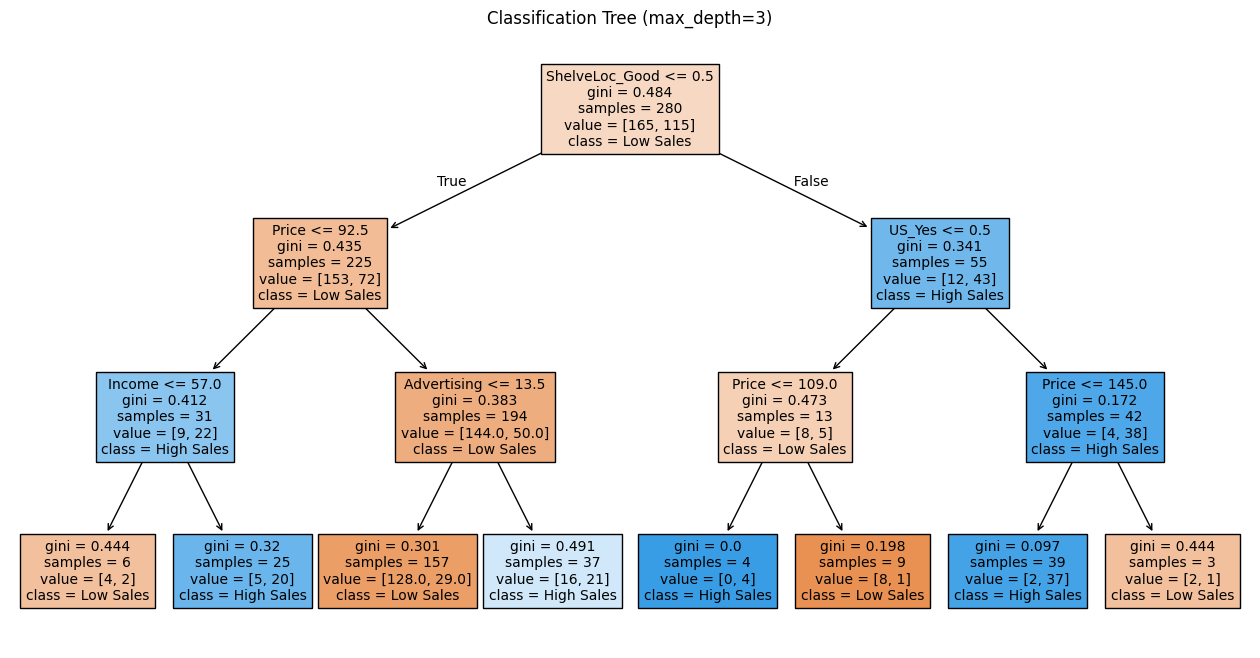

Train accuracy: 0.8
Test accuracy:  0.8


In [7]:
# fit classification tree with maximum depth of 3
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree3.fit(X_train, y_train)

# visualize the classification tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree3,
    feature_names=list(X.columns),
    class_names=['Low Sales', 'High Sales'],
    filled=True,
    fontsize=10
)

plt.title('Classification Tree (max_depth=3)')
plt.show()

# compare training and test accuracy
print('Train accuracy:', round(tree3.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree3.score(X_test, y_test), 3))


**Results:**

## Part 2 - Investigate Overfitting

**


### 2.1 Compare tree depths using 5-fold cv

In [8]:
# compare tree depths from 1 to 10 using 5-fold cross-validation
depths = range(1, 11)
cv_accuracy = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_accuracy.append(scores.mean())

    print(f"Depth {d}: Mean CV accuracy = {scores.mean():.3f}")

Depth 1: Mean CV accuracy = 0.668
Depth 2: Mean CV accuracy = 0.682
Depth 3: Mean CV accuracy = 0.711
Depth 4: Mean CV accuracy = 0.729
Depth 5: Mean CV accuracy = 0.693
Depth 6: Mean CV accuracy = 0.732
Depth 7: Mean CV accuracy = 0.714
Depth 8: Mean CV accuracy = 0.729
Depth 9: Mean CV accuracy = 0.721
Depth 10: Mean CV accuracy = 0.718


***Note to self:***

### 2.2 Graph tree depth versus cv accuracy

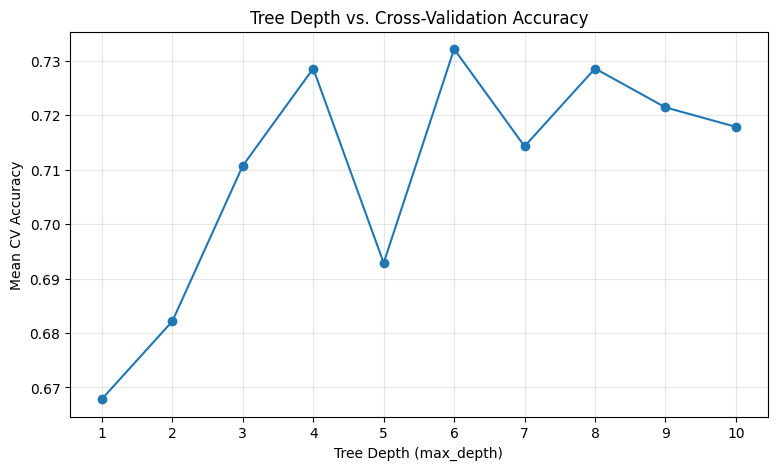

In [9]:
plt.figure(figsize=(9, 5)) # plot tree depth against mean cross-validation accuracy

plt.plot(depths, cv_accuracy, marker='o')

plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('Mean CV Accuracy')
plt.title('Tree Depth vs. Cross-Validation Accuracy')
plt.xticks(list(depths))
plt.grid(alpha=0.3)
plt.show()

### 2.3 Identify the best depth

In [10]:
# select the depth with the highest mean CV accuracy
best_depth = depths[cv_accuracy.index(max(cv_accuracy))]

print('Best max_depth:', best_depth)
print('Best mean CV accuracy:', round(max(cv_accuracy), 3))

Best max_depth: 6
Best mean CV accuracy: 0.732


***Note to self:***

### 2.4 Train and evaluate final tree

In [11]:
# train final classification tree using the best depth
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)

# evaluate the final tree on the test set
print('Final tree depth:', best_depth)
print('Final test accuracy:', round(final_tree.score(X_test, y_test), 3))

Final tree depth: 6
Final test accuracy: 0.733


**Results:**